# Chicago Food Inspections | Six Findings & Charts

**BA780 — Business Analytics • Individual inspection deep dive**  
**Study period:** January 2010–September 2026 (2010 data start January 4; 2026 is incomplete)  
**Source:** Four Chicago Food Inspections ZIP archives supplied by the project team.

### Research questions

1. Which inspection types have the highest recorded failure rates?
2. How do results vary among facility types and official risk classifications?
3. Did conditional-pass outcomes change over time?
4. Do failure rates differ across ZIP codes and calendar months?

**Read this before the charts:** All failure percentages below use **graded inspections only**: `Fail ÷ (Pass + Pass w/ Conditions + Fail)`. Other results (e.g., *Out of Business*, *No Entry*) are not counted in the failure-rate denominator. Inspection records are **not** a random sample of Chicago food businesses. Comparisons describe recorded results, not causal effects.

This notebook can be uploaded to GitHub as a **single `.ipynb` file**. Its figures and tables are saved in cell outputs. It also contains a small, verified **aggregate snapshot**—no individual business records—so **Run All works even without the raw ZIP files**. For full raw-data reproducibility, place the four food-inspection ZIP files in a local `data/` folder next to this notebook; the notebook will automatically recalculate the same charts from those files.

## 0. Setup, provenance, and reproducibility

Only `pandas`, `numpy`, `matplotlib`, and standard Python libraries are needed. When all four ZIPs are available, the script loads the real records, removes duplicate inspection IDs, keeps rows whose `City` field equals `Chicago`, and recalculates every displayed aggregate. Without the files, it uses the included verified aggregate snapshot. These are **summaries of the supplied data**, not hypothetical examples.

In [1]:
from pathlib import Path
import io, json, re, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 115, 'savefig.dpi': 125, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
                     'axes.labelsize': 10, 'font.size': 10})
BLUE='#2359A5'; GREEN='#0D9075'; RED='#CA524C'; GOLD='#C57B25'; LIGHT='#A7BBD0'

EXPECTED_PARTS = ['1', '2a', '2b', '3']
CANDIDATE_DIRS = [Path('data'), Path('.')]
archives = {}
for part in EXPECTED_PARTS:
    matches = []
    for folder in CANDIDATE_DIRS:
        matches += sorted(folder.glob(f'Food_Inspections_part_{part}*.zip'))
    if matches:
        archives[part] = matches[0]
print('Python packages loaded. Looking for four food-inspection source archives.')

Python packages loaded. Looking for four food-inspection source archives.


In [2]:
SNAPSHOT = json.loads('{"overview":{"inspections_chicago":314912,"graded":270371,"failures":60654,"condition_pass":46751,"unique_facilities_with_license":48876},"type":[{"Inspection Type":"Canvass","n":131699,"fail":29831,"conditional":27011,"failure_pct":22.65,"conditional_pct":20.51},{"Inspection Type":"License","n":36937,"fail":12542,"conditional":3849,"failure_pct":33.96,"conditional_pct":10.42},{"Inspection Type":"Canvass Re-Inspection","n":34686,"fail":3033,"conditional":4197,"failure_pct":8.74,"conditional_pct":12.1},{"Inspection Type":"Complaint","n":28160,"fail":9916,"conditional":6395,"failure_pct":35.21,"conditional_pct":22.71},{"Inspection Type":"License Re-Inspection","n":12635,"fail":1368,"conditional":1341,"failure_pct":10.83,"conditional_pct":10.61},{"Inspection Type":"Complaint Re-Inspection","n":12340,"fail":1411,"conditional":1539,"failure_pct":11.43,"conditional_pct":12.47}],"facility":[{"Facility Type":"Restaurant","n":183866,"fail":39867,"conditional":35158,"failure_pct":21.68,"conditional_pct":19.12},{"Facility Type":"Grocery Store","n":32670,"fail":8534,"conditional":5443,"failure_pct":26.12,"conditional_pct":16.66},{"Facility Type":"School","n":19080,"fail":4271,"conditional":1773,"failure_pct":22.38,"conditional_pct":9.29},{"Facility Type":"Bakery","n":3879,"fail":953,"conditional":624,"failure_pct":24.57,"conditional_pct":16.09},{"Facility Type":"Hospital","n":930,"fail":151,"conditional":141,"failure_pct":16.24,"conditional_pct":15.16}],"risk":[{"Risk":"Risk 1 (High)","n":205631,"fail":44911,"conditional":36360,"failure_pct":21.84,"conditional_pct":17.68},{"Risk":"Risk 2 (Medium)","n":47216,"fail":10641,"conditional":8325,"failure_pct":22.54,"conditional_pct":17.63},{"Risk":"Risk 3 (Low)","n":17483,"fail":5075,"conditional":2066,"failure_pct":29.03,"conditional_pct":11.82}],"zip":[{"Zip":60614.0,"n":9790,"fail":2288,"conditional":2149,"failure_pct":23.37,"conditional_pct":21.95},{"Zip":60647.0,"n":9597,"fail":2270,"conditional":1656,"failure_pct":23.65,"conditional_pct":17.26},{"Zip":60657.0,"n":8969,"fail":2004,"conditional":1678,"failure_pct":22.34,"conditional_pct":18.71},{"Zip":60611.0,"n":8892,"fail":1540,"conditional":1821,"failure_pct":17.32,"conditional_pct":20.48},{"Zip":60608.0,"n":8224,"fail":1971,"conditional":1269,"failure_pct":23.97,"conditional_pct":15.43},{"Zip":60622.0,"n":8210,"fail":1912,"conditional":1442,"failure_pct":23.29,"conditional_pct":17.56},{"Zip":60618.0,"n":8200,"fail":1530,"conditional":1425,"failure_pct":18.66,"conditional_pct":17.38},{"Zip":60607.0,"n":7641,"fail":1635,"conditional":1480,"failure_pct":21.4,"conditional_pct":19.37},{"Zip":60625.0,"n":7350,"fail":1835,"conditional":1373,"failure_pct":24.97,"conditional_pct":18.68},{"Zip":60639.0,"n":7192,"fail":1921,"conditional":1293,"failure_pct":26.71,"conditional_pct":17.98},{"Zip":60640.0,"n":7172,"fail":1689,"conditional":1374,"failure_pct":23.55,"conditional_pct":19.16},{"Zip":60616.0,"n":7160,"fail":1709,"conditional":1087,"failure_pct":23.87,"conditional_pct":15.18},{"Zip":60632.0,"n":6516,"fail":1509,"conditional":1154,"failure_pct":23.16,"conditional_pct":17.71},{"Zip":60623.0,"n":6320,"fail":1663,"conditional":927,"failure_pct":26.31,"conditional_pct":14.67},{"Zip":60654.0,"n":6068,"fail":1066,"conditional":1423,"failure_pct":17.57,"conditional_pct":23.45},{"Zip":60613.0,"n":6011,"fail":1244,"conditional":1214,"failure_pct":20.7,"conditional_pct":20.2},{"Zip":60609.0,"n":5738,"fail":1299,"conditional":825,"failure_pct":22.64,"conditional_pct":14.38},{"Zip":60610.0,"n":5484,"fail":1080,"conditional":1112,"failure_pct":19.69,"conditional_pct":20.28},{"Zip":60617.0,"n":5444,"fail":1409,"conditional":785,"failure_pct":25.88,"conditional_pct":14.42},{"Zip":60659.0,"n":5370,"fail":1363,"conditional":907,"failure_pct":25.38,"conditional_pct":16.89},{"Zip":60619.0,"n":5340,"fail":1591,"conditional":765,"failure_pct":29.79,"conditional_pct":14.33},{"Zip":60634.0,"n":5328,"fail":997,"conditional":910,"failure_pct":18.71,"conditional_pct":17.08},{"Zip":60629.0,"n":5233,"fail":1117,"conditional":716,"failure_pct":21.35,"conditional_pct":13.68},{"Zip":60620.0,"n":5152,"fail":1457,"conditional":782,"failure_pct":28.28,"conditional_pct":15.18},{"Zip":60628.0,"n":4837,"fail":1379,"conditional":755,"failure_pct":28.51,"conditional_pct":15.61},{"Zip":60641.0,"n":4753,"fail":964,"conditional":861,"failure_pct":20.28,"conditional_pct":18.11},{"Zip":60601.0,"n":4580,"fail":676,"conditional":802,"failure_pct":14.76,"conditional_pct":17.51},{"Zip":60612.0,"n":4510,"fail":1008,"conditional":686,"failure_pct":22.35,"conditional_pct":15.21},{"Zip":60605.0,"n":4345,"fail":905,"conditional":771,"failure_pct":20.83,"conditional_pct":17.74},{"Zip":60606.0,"n":4215,"fail":599,"conditional":906,"failure_pct":14.21,"conditional_pct":21.49},{"Zip":60626.0,"n":4059,"fail":1003,"conditional":721,"failure_pct":24.71,"conditional_pct":17.76},{"Zip":60660.0,"n":4009,"fail":995,"conditional":729,"failure_pct":24.82,"conditional_pct":18.18},{"Zip":60643.0,"n":3908,"fail":864,"conditional":589,"failure_pct":22.11,"conditional_pct":15.07},{"Zip":60666.0,"n":3831,"fail":473,"conditional":731,"failure_pct":12.35,"conditional_pct":19.08},{"Zip":60651.0,"n":3770,"fail":1062,"conditional":537,"failure_pct":28.17,"conditional_pct":14.24},{"Zip":60630.0,"n":3768,"fail":848,"conditional":647,"failure_pct":22.51,"conditional_pct":17.17},{"Zip":60638.0,"n":3716,"fail":547,"conditional":478,"failure_pct":14.72,"conditional_pct":12.86},{"Zip":60661.0,"n":3635,"fail":611,"conditional":780,"failure_pct":16.81,"conditional_pct":21.46},{"Zip":60642.0,"n":3440,"fail":737,"conditional":669,"failure_pct":21.42,"conditional_pct":19.45},{"Zip":60644.0,"n":3256,"fail":884,"conditional":449,"failure_pct":27.15,"conditional_pct":13.79},{"Zip":60637.0,"n":3246,"fail":864,"conditional":398,"failure_pct":26.62,"conditional_pct":12.26},{"Zip":60649.0,"n":3226,"fail":782,"conditional":491,"failure_pct":24.24,"conditional_pct":15.22},{"Zip":60615.0,"n":3223,"fail":835,"conditional":534,"failure_pct":25.91,"conditional_pct":16.57},{"Zip":60636.0,"n":3074,"fail":864,"conditional":401,"failure_pct":28.11,"conditional_pct":13.04},{"Zip":60624.0,"n":2829,"fail":758,"conditional":395,"failure_pct":26.79,"conditional_pct":13.96},{"Zip":60603.0,"n":2567,"fail":435,"conditional":473,"failure_pct":16.95,"conditional_pct":18.43},{"Zip":60653.0,"n":2408,"fail":572,"conditional":344,"failure_pct":23.75,"conditional_pct":14.29},{"Zip":60652.0,"n":2400,"fail":409,"conditional":348,"failure_pct":17.04,"conditional_pct":14.5},{"Zip":60621.0,"n":2333,"fail":646,"conditional":298,"failure_pct":27.69,"conditional_pct":12.77},{"Zip":60631.0,"n":2036,"fail":403,"conditional":375,"failure_pct":19.79,"conditional_pct":18.42},{"Zip":60602.0,"n":2020,"fail":361,"conditional":334,"failure_pct":17.87,"conditional_pct":16.53},{"Zip":60646.0,"n":1937,"fail":362,"conditional":282,"failure_pct":18.69,"conditional_pct":14.56},{"Zip":60645.0,"n":1851,"fail":462,"conditional":314,"failure_pct":24.96,"conditional_pct":16.96},{"Zip":60604.0,"n":1675,"fail":260,"conditional":309,"failure_pct":15.52,"conditional_pct":18.45},{"Zip":60707.0,"n":1470,"fail":349,"conditional":283,"failure_pct":23.74,"conditional_pct":19.25},{"Zip":60655.0,"n":1218,"fail":213,"conditional":185,"failure_pct":17.49,"conditional_pct":15.19},{"Zip":60656.0,"n":1077,"fail":223,"conditional":202,"failure_pct":20.71,"conditional_pct":18.76}],"month":[{"Month":5,"n":25327,"fail":5531,"conditional":4187,"failure_pct":21.84,"conditional_pct":16.53},{"Month":3,"n":24553,"fail":5402,"conditional":4134,"failure_pct":22.0,"conditional_pct":16.84},{"Month":6,"n":24443,"fail":5583,"conditional":4243,"failure_pct":22.84,"conditional_pct":17.36},{"Month":4,"n":24178,"fail":5402,"conditional":4034,"failure_pct":22.34,"conditional_pct":16.68},{"Month":8,"n":23771,"fail":5705,"conditional":4454,"failure_pct":24.0,"conditional_pct":18.74},{"Month":10,"n":23770,"fail":5407,"conditional":3914,"failure_pct":22.75,"conditional_pct":16.47},{"Month":9,"n":23338,"fail":5471,"conditional":3959,"failure_pct":23.44,"conditional_pct":16.96},{"Month":1,"n":21650,"fail":4832,"conditional":3686,"failure_pct":22.32,"conditional_pct":17.03},{"Month":7,"n":20632,"fail":4812,"conditional":4070,"failure_pct":23.32,"conditional_pct":19.73},{"Month":2,"n":20441,"fail":4587,"conditional":3494,"failure_pct":22.44,"conditional_pct":17.09},{"Month":11,"n":20096,"fail":4304,"conditional":3414,"failure_pct":21.42,"conditional_pct":16.99},{"Month":12,"n":18172,"fail":3618,"conditional":3162,"failure_pct":19.91,"conditional_pct":17.4}],"annual":[{"Year":2016,"n":19843,"fail":4294,"conditional":2633,"failure_pct":21.64,"conditional_pct":13.27},{"Year":2014,"n":18600,"fail":3711,"conditional":2308,"failure_pct":19.95,"conditional_pct":12.41},{"Year":2017,"n":18455,"fail":4110,"conditional":2131,"failure_pct":22.27,"conditional_pct":11.55},{"Year":2015,"n":17877,"fail":3605,"conditional":2155,"failure_pct":20.17,"conditional_pct":12.05},{"Year":2011,"n":17547,"fail":4346,"conditional":1516,"failure_pct":24.77,"conditional_pct":8.64},{"Year":2010,"n":17344,"fail":4488,"conditional":1425,"failure_pct":25.88,"conditional_pct":8.22},{"Year":2013,"n":17050,"fail":3343,"conditional":1755,"failure_pct":19.61,"conditional_pct":10.29},{"Year":2019,"n":16099,"fail":3608,"conditional":7927,"failure_pct":22.41,"conditional_pct":49.24},{"Year":2025,"n":16024,"fail":3384,"conditional":2275,"failure_pct":21.12,"conditional_pct":14.2},{"Year":2012,"n":15979,"fail":3635,"conditional":1530,"failure_pct":22.75,"conditional_pct":9.58},{"Year":2024,"n":15957,"fail":3478,"conditional":2602,"failure_pct":21.8,"conditional_pct":16.31},{"Year":2023,"n":15391,"fail":3831,"conditional":2351,"failure_pct":24.89,"conditional_pct":15.28},{"Year":2018,"n":14824,"fail":3315,"conditional":5154,"failure_pct":22.36,"conditional_pct":34.77},{"Year":2022,"n":14263,"fail":3547,"conditional":2499,"failure_pct":24.87,"conditional_pct":17.52},{"Year":2021,"n":13109,"fail":3027,"conditional":3181,"failure_pct":23.09,"conditional_pct":24.27},{"Year":2020,"n":12578,"fail":2926,"conditional":3927,"failure_pct":23.26,"conditional_pct":31.22},{"Year":2026,"n":9431,"fail":2006,"conditional":1382,"failure_pct":21.27,"conditional_pct":14.65}]}')
print('Verified snapshot ready: 314,912 Chicago inspections; 270,371 graded; 60,654 failures.')

Verified snapshot ready: 314,912 Chicago inspections; 270,371 graded; 60,654 failures.


In [3]:
def summarize_raw_files(files):
    wanted = ['Inspection ID','Results','Risk','Facility Type','Inspection Type',
              'Zip','Inspection Date','City']
    parts = []
    for part in EXPECTED_PARTS:
        with zipfile.ZipFile(files[part]) as z:
            csv_names = [n for n in z.namelist() if n.lower().endswith('.csv')]
            if len(csv_names) != 1:
                raise ValueError(f'{files[part]}: expected one CSV, found {len(csv_names)}')
            with z.open(csv_names[0]) as file:
                chunk = pd.read_csv(file, usecols=wanted, low_memory=False)
        parts.append(chunk)
    raw = pd.concat(parts, ignore_index=True)
    before = len(raw)
    raw = raw.drop_duplicates(subset=['Inspection ID'], keep='last')
    city = raw['City'].astype('string').str.strip().str.upper().eq('CHICAGO').fillna(False)
    clean = raw[city].copy()
    del raw,parts
    clean['Date'] = pd.to_datetime(clean['Inspection Date'], errors='coerce')
    clean['Year'] = clean['Date'].dt.year
    clean['Month'] = clean['Date'].dt.month
    clean['Result'] = clean['Results'].astype('string').str.strip().str.upper().replace({
        'PASS WITH CONDITIONS':'PASS W/ CONDITIONS'})
    clean['Fail'] = clean['Result'].eq('FAIL').fillna(False)
    clean['Conditional'] = clean['Result'].eq('PASS W/ CONDITIONS').fillna(False)
    grades = clean[clean['Result'].isin(['PASS','FAIL','PASS W/ CONDITIONS'])].copy()

    def group(field):
        agg = (grades.groupby(field, dropna=False).agg(
                n=('Inspection ID','size'), fail=('Fail','sum'),
                conditional=('Conditional','sum')).reset_index())
        agg['failure_pct'] = (100 * agg['fail'] / agg['n']).round(2)
        agg['conditional_pct'] = (100 * agg['conditional'] / agg['n']).round(2)
        return agg.to_dict('records')

    sums = {'overview':{'inspections_chicago':len(clean), 'graded':len(grades),
                         'failures':int(grades['Fail'].sum()),
                         'condition_pass':int(grades['Conditional'].sum())},
            'type': group('Inspection Type'), 'facility':group('Facility Type'),
            'risk':group('Risk'), 'zip':group('Zip'), 'month':group('Month'),
            'annual':group('Year')}
    print(f'Loaded {before:,} raw records, retained {len(clean):,} Chicago inspections.')
    return sums

if len(archives) == 4:
    summary = summarize_raw_files(archives)
    mode = 'FULL RAW-DATA RECOMPUTATION'
else:
    if archives:
        print('Partial ZIP collection detected; using complete verified snapshot instead of partial data.')
    summary = SNAPSHOT
    mode = 'VERIFIED AGGREGATE SNAPSHOT'

counts = summary['overview']
rate = 100*counts['failures']/counts['graded']
print('Data mode:', mode)
print(f"Inspections: {counts['inspections_chicago']:,} | Graded: {counts['graded']:,} | "
      f"Failures: {counts['failures']:,} | Graded failure rate: {rate:.2f}%")
assert counts['graded'] >= counts['failures'] > 0

def table(name):
    d = pd.DataFrame(summary[name]).copy()
    if 'failure_pct' not in d.columns and 'n' in d.columns:
        d['failure_pct'] = (100*d['fail']/d['n']).round(2)
    if 'conditional_pct' not in d.columns and 'n' in d.columns:
        d['conditional_pct'] = (100*d['conditional']/d['n']).round(2)
    return d

Loaded 315,488 raw records, retained 314,912 Chicago inspections.
Data mode: FULL RAW-DATA RECOMPUTATION
Inspections: 314,912 | Graded: 270,371 | Failures: 60,654 | Graded failure rate: 22.43%


### Data audit

| Metric | Verified result |
|---|---:|
| Records across four input archives | 315,488 |
| Retained rows labeled Chicago after deduplication | 314,912 |
| Graded inspections | 270,371 |
| Fail results | 60,654 |
| **Overall failure percentage among graded inspections** | **22.43%** |

**Cautions:** There are also ungraded outcomes in the source (including *Out of Business* and *No Entry*). `Inspection ID` identifies an inspection event, not a unique restaurant; a facility may appear many times. City filtering excludes records whose city label is not `CHICAGO`, even if they might otherwise be geographically relevant.

## 1. Inspection type: complaint inspections fail more often

**Question:** Does inspection type correspond to failure outcomes?  
**Finding:** Complaint inspections recorded **35.2% fails** among graded outcomes, compared with **22.7%** for routine canvass inspections. Re-inspections have lower recorded rates, but their populations and circumstances differ.

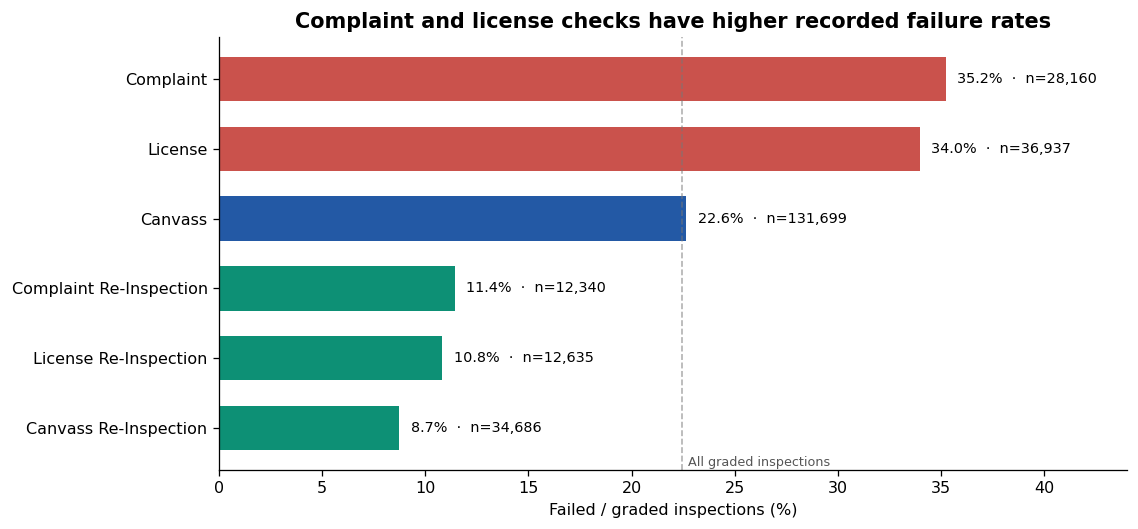

,Graded inspections,Fails,Failure rate (%)
Inspection Type,,,
Complaint,28160,9916,35.21
License,36937,12542,33.96
Canvass,131699,29831,22.65
Complaint Re-Inspection,12340,1411,11.43
License Re-Inspection,12635,1368,10.83
Canvass Re-Inspection,34686,3033,8.74


In [4]:
labels=['Complaint','License','Canvass','Complaint Re-Inspection','License Re-Inspection','Canvass Re-Inspection']
d = table('type').set_index('Inspection Type').reindex(labels)
assert d['n'].notna().all(), 'Expected inspection types not found.'
fig,ax=plt.subplots(figsize=(10,4.7))
y=np.arange(len(d)); colors=[RED,RED,BLUE,GREEN,GREEN,GREEN]
ax.barh(y,d['failure_pct'],color=colors,height=.64)
ax.set_yticks(y,labels);ax.invert_yaxis();ax.set_xlim(0,44)
ax.set_xlabel('Failed / graded inspections (%)')
ax.set_title('Complaint and license checks have higher recorded failure rates')
for i,row in enumerate(d.itertuples()):
    ax.text(row.failure_pct+.55,i,f'{row.failure_pct:.1f}%  ·  n={int(row.n):,}',va='center',fontsize=9)
ax.axvline(rate,color='#777777',ls='--',lw=1,alpha=.6)
ax.text(rate+.3,5.55,'All graded inspections',fontsize=8,color='#555555')
plt.tight_layout();plt.show()
display(d[['n','fail','failure_pct']].rename(columns={'n':'Graded inspections','fail':'Fails','failure_pct':'Failure rate (%)'}))

**Interpretation:** Higher complaint-inspection failure rates are consistent with inspections being initiated after a reported concern. They are **not evidence that responding to complaints causes failures**. Comparing a routine initial inspection with a re-inspection is particularly susceptible to selection and follow-up effects.

## 2. Facility type: grocery stores exceed restaurants

**Finding:** In graded inspections, grocery stores had a **26.1% failure rate** compared with **21.7%** for restaurants (about **4.4 percentage points higher**). Facility categories differ substantially in size and operating requirements.

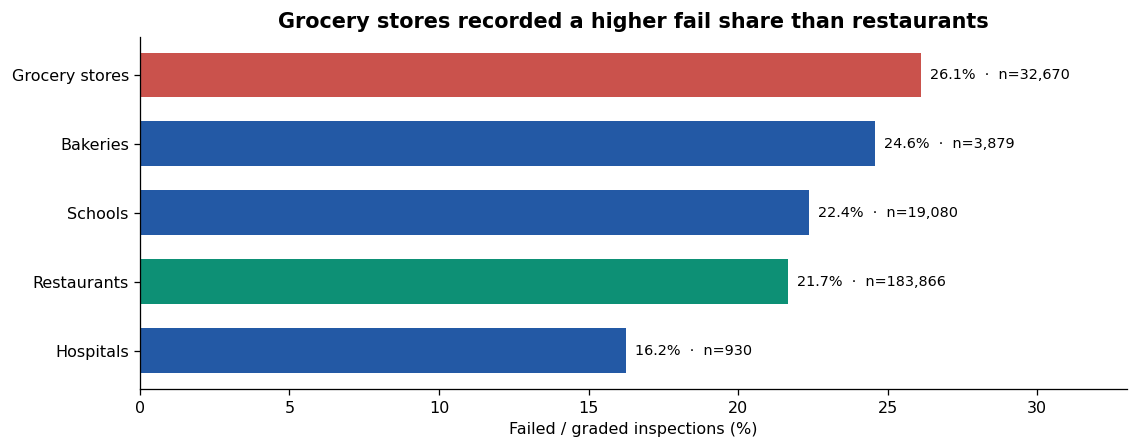

,Graded inspections,Fails,Failure rate (%)
Facility Type,,,
Grocery Store,32670,8534,26.12
Bakery,3879,953,24.57
School,19080,4271,22.38
Restaurant,183866,39867,21.68
Hospital,930,151,16.24


In [5]:
labels=['Grocery Store','Bakery','School','Restaurant','Hospital']
d=table('facility').set_index('Facility Type').reindex(labels)
assert d['n'].notna().all()
fig,ax=plt.subplots(figsize=(10,4))
y=np.arange(len(d))
ax.barh(y,d['failure_pct'],color=[RED,BLUE,BLUE,GREEN,BLUE],height=.65)
ax.set_yticks(y,['Grocery stores','Bakeries','Schools','Restaurants','Hospitals'])
ax.invert_yaxis();ax.set_xlim(0,33)
ax.set_xlabel('Failed / graded inspections (%)')
ax.set_title('Grocery stores recorded a higher fail share than restaurants')
for i,row in enumerate(d.itertuples()):
    ax.text(row.failure_pct+.3,i,f'{row.failure_pct:.1f}%  ·  n={int(row.n):,}',va='center',fontsize=9)
plt.tight_layout();plt.show()
display(d[['n','fail','failure_pct']].rename(columns={'n':'Graded inspections','fail':'Fails','failure_pct':'Failure rate (%)'}))

**Interpretation:** This is a descriptive comparison, not a ranking of food safety. A stronger next step is to compare facility types **within the same inspection type and year**, because inspections are scheduled and triggered differently.

## 3. Official risk category: the counterintuitive Risk 3 result

**Finding:** Facilities marked **Risk 3 (Low)** had the highest recorded fail percentage of the three specified risk categories (**29.0%**) versus **21.8%** for Risk 1 (High).

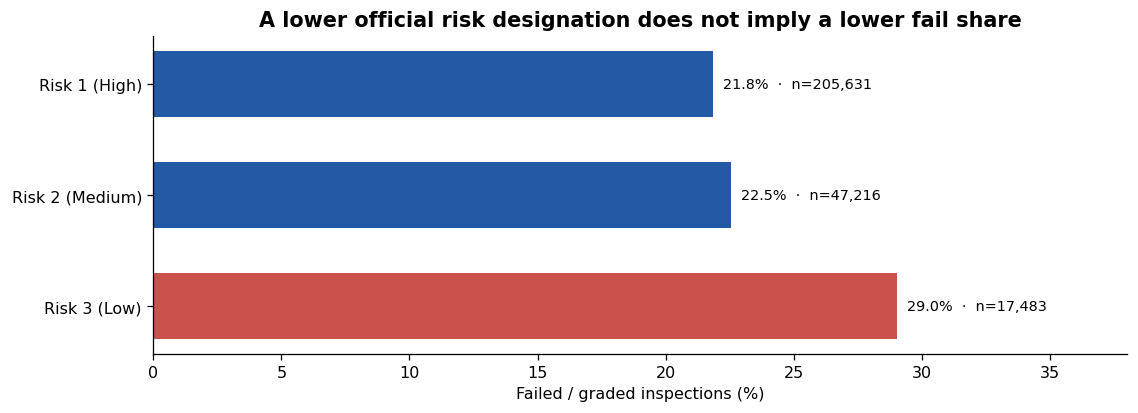

,Graded inspections,Fails,Failure rate (%)
Risk,,,
Risk 1 (High),205631,44911,21.84
Risk 2 (Medium),47216,10641,22.54
Risk 3 (Low),17483,5075,29.03


In [6]:
labels=['Risk 1 (High)','Risk 2 (Medium)','Risk 3 (Low)']
d=table('risk').set_index('Risk').reindex(labels)
fig,ax=plt.subplots(figsize=(10,3.7))
y=np.arange(len(d));ax.barh(y,d['failure_pct'],color=[BLUE,BLUE,RED],height=.60)
ax.set_yticks(y,labels);ax.invert_yaxis();ax.set_xlim(0,38)
ax.set_xlabel('Failed / graded inspections (%)')
ax.set_title('A lower official risk designation does not imply a lower fail share')
for i,row in enumerate(d.itertuples()):
    ax.text(row.failure_pct+.4,i,f'{row.failure_pct:.1f}%  ·  n={int(row.n):,}',va='center',fontsize=9)
plt.tight_layout();plt.show()
display(d[['n','fail','failure_pct']].rename(columns={'n':'Graded inspections','fail':'Fails','failure_pct':'Failure rate (%)'}))

**Interpretation:** Chicago's official *risk classification* is **not** the same thing as the *measured probability of inspection failure*. Low-risk facilities may have different business and inspection mixes. Do **not** conclude that Risk 3 facilities are inherently less safe or more hazardous.

## 4. Conditional passes surged during 2018–2019

**Finding:** The share of **Pass w/ Conditions** outcomes among graded inspections rose from **11.6% in 2017** to **49.2% in 2019**, then fell to **14.2% in 2025**. This is the most pronounced change in outcome composition in the time series.

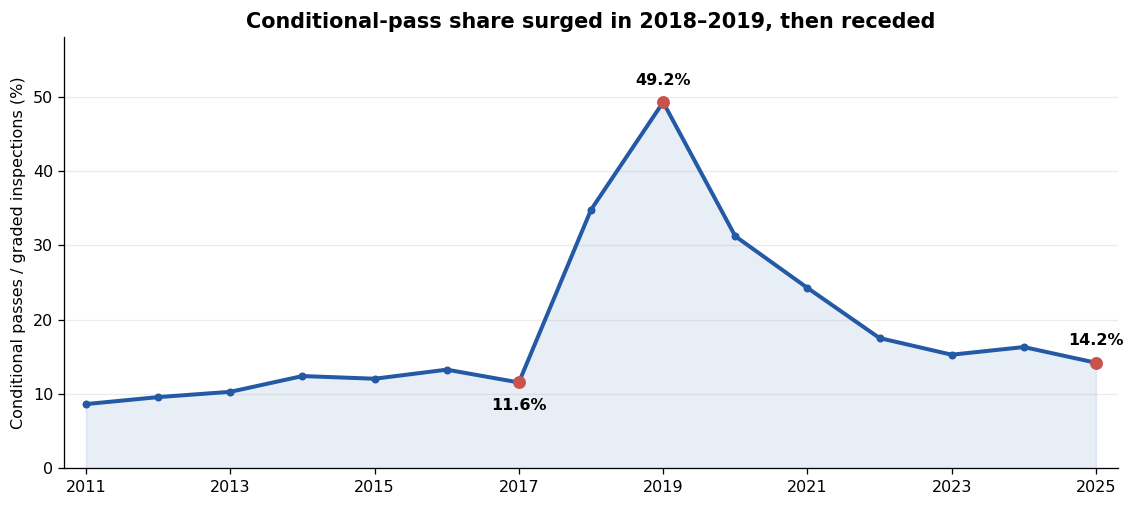

,Year,Graded inspections,Conditional passes,Conditional rate (%)
7,2017,18455,2131,11.55
8,2018,14824,5154,34.77
9,2019,16099,7927,49.24
10,2020,12578,3927,31.22
15,2025,16024,2275,14.20


In [7]:
d=table('annual').dropna(subset=['Year']).copy()
d['Year']=pd.to_numeric(d['Year'],errors='coerce')
d=d[d['Year'].between(2011,2025)].sort_values('Year')
fig,ax=plt.subplots(figsize=(10,4.5))
ax.plot(d['Year'],d['conditional_pct'],color=BLUE,linewidth=2.5,marker='o',markersize=4)
ax.fill_between(d['Year'].to_numpy(float),d['conditional_pct'].to_numpy(float),alpha=.10,color=BLUE)
for yr in [2017,2019,2025]:
    row=d.loc[d['Year'].eq(yr)].iloc[0]
    ax.scatter([yr],[row['conditional_pct']],s=50,color=RED,zorder=3)
    offset=(0,11) if yr!=2017 else (0,-17)
    ax.annotate(f"{row['conditional_pct']:.1f}%",(yr,row['conditional_pct']),
                textcoords='offset points',xytext=offset,ha='center',fontsize=10,fontweight='bold')
ax.set_ylim(0,58);ax.set_xlim(2010.7,2025.3)
ax.set_xticks(np.arange(2011,2026,2));ax.set_ylabel('Conditional passes / graded inspections (%)')
ax.set_title('Conditional-pass share surged in 2018–2019, then receded')
ax.grid(axis='y',alpha=.25);plt.tight_layout();plt.show()
display(d.loc[d['Year'].isin([2017,2018,2019,2020,2025]),
              ['Year','n','conditional','conditional_pct']].rename(columns={
                'n':'Graded inspections','conditional':'Conditional passes','conditional_pct':'Conditional rate (%)'}))

**Interpretation:** The data establishes **when** the shares changed, not **why**. Candidate explanations to test include revisions to inspection policy, inspection types, data entry practices, or changes in inspected facilities. We did **not** verify a regulatory change, so do not label one as the cause. Years 2011–2025 are used here because 2026 is incomplete; this chart uses 2011–2025 for a consistent full-year window.

## 5. ZIP-code variation: some areas show notably higher failure shares

**Finding:** ZIPs **60619 (29.8%)**, **60628 (28.5%)**, and **60620 (28.3%)** had substantially higher recorded failure percentages than, for example, **60611 (17.3%)**. To limit small-denominator noise, this chart compares the five highest and five lowest observed ZIP-level rates **among ZIPs with at least 2,000 graded inspections**.

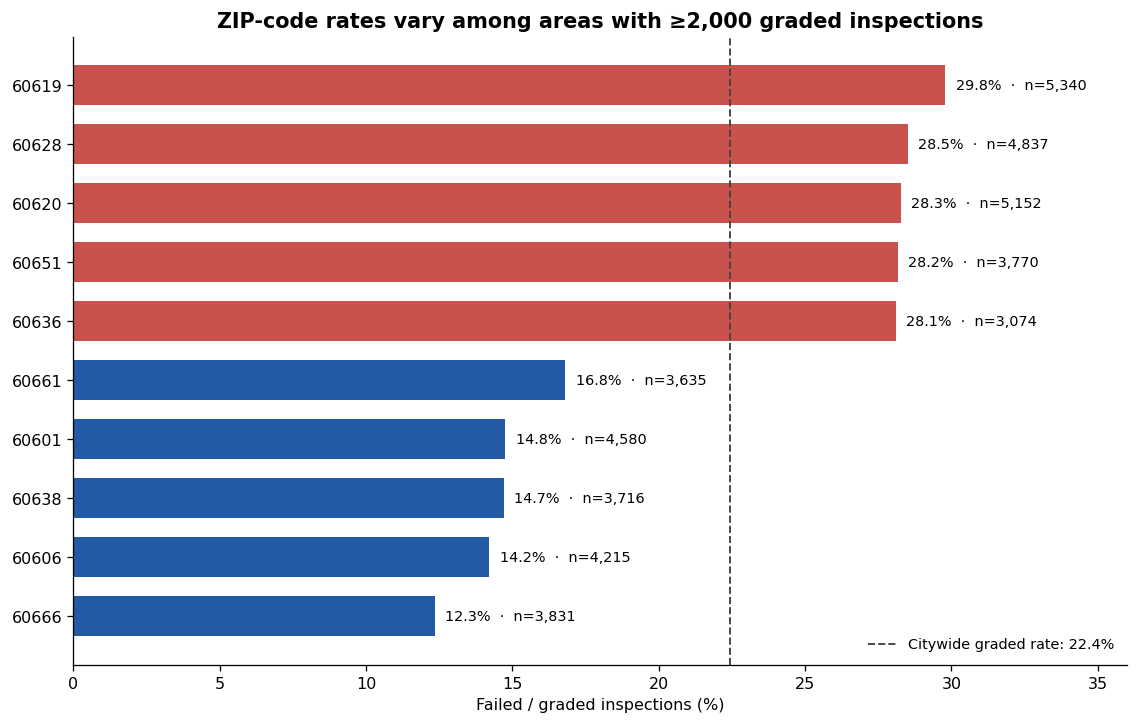

,ZIP code,Graded inspections,Fails,Failure rate (%)
19,60619,5340,1591,29.79
28,60628,4837,1379,28.51
20,60620,5152,1457,28.28
48,60651,3770,1062,28.17
35,60636,3074,864,28.11
57,60661,3635,611,16.81
1,60601,4580,676,14.76
37,60638,3716,547,14.72
6,60606,4215,599,14.21
58,60666,3831,473,12.35


In [8]:
d=table('zip').dropna(subset=['Zip']).copy()
d['ZIP5'] = pd.to_numeric(d['Zip'],errors='coerce').astype('Int64').astype('string').str.zfill(5)
d=d[d['ZIP5'].str.fullmatch(r'\d{5}',na=False) & d['n'].ge(2000)].copy()
assert len(d)>=10,'Not enough sufficiently sampled ZIP codes.'
hi=d.nlargest(5,'failure_pct');lo=d.nsmallest(5,'failure_pct')
selected=pd.concat([hi,lo]).sort_values('failure_pct',ascending=True)
fig,ax=plt.subplots(figsize=(10,6.4))
y=np.arange(len(selected))
colors=[RED if val in set(hi['ZIP5']) else BLUE for val in selected['ZIP5']]
ax.barh(y,selected['failure_pct'],color=colors,height=.68)
ax.set_yticks(y,selected['ZIP5']);ax.set_xlim(0,36)
ax.set_xlabel('Failed / graded inspections (%)')
ax.set_title('ZIP-code rates vary among areas with ≥2,000 graded inspections')
ax.axvline(rate,color='#444444',ls='--',linewidth=1.2,label=f'Citywide graded rate: {rate:.1f}%')
for i,row in enumerate(selected.itertuples()):
    ax.text(row.failure_pct+.35,i,f'{row.failure_pct:.1f}%  ·  n={int(row.n):,}',va='center',fontsize=9)
ax.legend(loc='lower right',frameon=False,fontsize=9)
plt.tight_layout();plt.show()
display(selected[['ZIP5','n','fail','failure_pct']].sort_values('failure_pct',ascending=False)
        .rename(columns={'ZIP5':'ZIP code','n':'Graded inspections','fail':'Fails','failure_pct':'Failure rate (%)'}))

**Interpretation:** ZIPs are **not adjusted for business counts, facility category, inspection type, or inspection frequency**. The chart shows where recorded inspection outcomes differ; it does **not** establish why those areas differ or rank the safety of residents or neighborhoods. An airport or business-district ZIP may have an unusual facility mix.

## 6. Seasonality: August's failure share exceeds December's

**Finding:** Across all graded records, the recorded failure share is **24.0% in August** and **19.9% in December** (approximately **4.1 percentage points apart**).

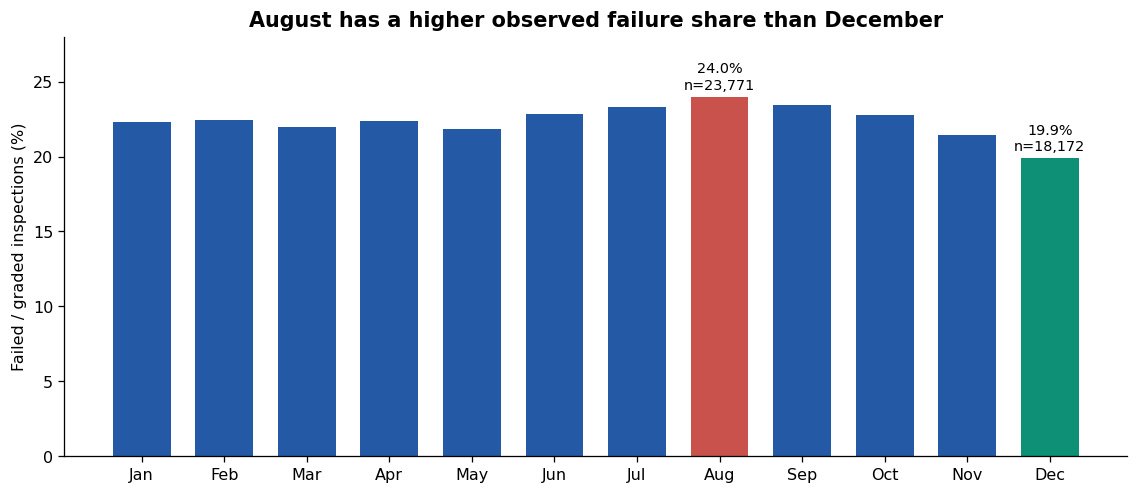

,Month,Graded inspections,Fails,Failure rate (%)
0,1,21650,4832,22.32
1,2,20441,4587,22.44
2,3,24553,5402,22.00
3,4,24178,5402,22.34
4,5,25327,5531,21.84
5,6,24443,5583,22.84
6,7,20632,4812,23.32
7,8,23771,5705,24.00
8,9,23338,5471,23.44
9,10,23770,5407,22.75


In [9]:
from calendar import month_abbr
d=table('month').dropna(subset=['Month']).copy()
d['Month']=pd.to_numeric(d['Month'],errors='coerce').astype(int)
d=d[d['Month'].between(1,12)].sort_values('Month')
fig,ax=plt.subplots(figsize=(10,4.4))
colors=[RED if m==8 else GREEN if m==12 else BLUE for m in d['Month']]
ax.bar(d['Month'],d['failure_pct'],color=colors,width=.7)
ax.set_xticks(d['Month'],[month_abbr[m] for m in d['Month']])
ax.set_ylim(0,28);ax.set_ylabel('Failed / graded inspections (%)')
ax.set_title('August has a higher observed failure share than December')
for r in d.itertuples():
    if r.Month in (8,12):
        ax.text(r.Month,r.failure_pct+.5,f'{r.failure_pct:.1f}%\nn={int(r.n):,}',ha='center',fontsize=9)
plt.tight_layout();plt.show()
display(d[['Month','n','fail','failure_pct']].rename(columns={
    'n':'Graded inspections','fail':'Fails','failure_pct':'Failure rate (%)'}))

**Interpretation:** This is a **pooled calendar-month pattern**, not proof that warm weather causes failure. Inspection composition, seasonal operation, scheduling, and coverage differences, especially the incomplete 2026 period, can influence the observed pattern. Next step: compare calendar months **within each complete year**, then inspect whether the August–December gap persists.

## 7. Conclusions for the BA780 presentation

**Six data-supported findings**

1. **Inspection type matters:** complaint inspections show a higher observed graded failure rate than routine canvass inspections.
2. **Facility categories differ:** grocery stores have a higher observed rate than restaurants in this dataset.
3. **Risk labels are not outcome probabilities:** *Risk 3 (Low)* has the highest failure share among the three major official risk categories.
4. **Outcome recording changed noticeably:** conditional passes peaked in 2019. The underlying explanation remains unverified.
5. **ZIP codes differ:** substantial variations remain even after requiring at least 2,000 graded inspections per ZIP.
6. **Calendar-month rates differ:** August's pooled failure share is higher than December's, but seasonality needs within-year testing.

**Recommended presentation flow:** inspection types → facility/risk mix → historical anomalies → geographic differences → limits and next steps. Use the ZIP and risk findings as **hypotheses for further investigation**, not final explanations.

### Important methodological limitations

- **Unit of analysis:** one inspection event, **not** one unique restaurant. A business can be inspected more than once.
- **Denominator:** only Pass, Pass w/ Conditions and Fail. Excluded outcomes are not silently counted as passes.
- **Selection bias:** complaint, license, canvass and re-inspection groups are not equivalent.
- **Confounders:** facility type, risk designation, neighborhood business mix, time period and enforcement practices may all affect results.
- **Temporal coverage:** 2026 is a partial year and historical coverage can vary; for longitudinal comparisons, use a defensible full-year window.
- **No causal inference:** these descriptive charts do not show that an inspection type, ZIP code, or calendar month *causes* a facility to fail.

### Suggested next analyses

- **Like-for-like comparisons:** failure percentage by facility type *within* routine canvass inspections, controlling for year and risk category.
- **Re-inspection follow-through:** assess whether individual facilities change outcomes between inspections, using license or location identifiers and inspection dates; avoid treating each re-inspection as independent.
- **Link to the team's sanitation notebook:** use standardized address-year summaries for exploratory association only, with match coverage and ambiguity explicitly reported.

**Repository placement:** `analysis/integrated_sanitation_food/BA780_Food_Inspection_Findings.ipynb`. GitHub renders this executed notebook and its figures without requiring readers to download the source ZIPs. For recomputation, use the original four archives in a local `data/` directory.